# Autoencoder ile Endüstriyel Sensör Verisinde Anomali Tespiti
**Proje türü:** Derin öğrenme – Anomali tespiti (Autoencoder)

Akış: veri üretimi/okuma → keşif → ön işleme (pencereleme, ölçekleme, zamansal bölme) →
autoencoder eğitimi (yalnızca normal veri) → eşik belirleme → değerlendirme → hata analizi.

In [ ]:
import os, json, copy, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve,
                             precision_recall_curve)
warnings.filterwarnings("ignore")

SEED = 42
rng = np.random.default_rng(SEED)
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)
DATA_SOURCE = "synthetic"      # "synthetic" veya "skab"
W = 10                         # pencere uzunluğu (10 dakikalık pencere)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 130, "savefig.bbox": "tight", "font.size": 9})
C_NORM, C_ANOM, C_AE = "#2b6cb0", "#c53030", "#2f855a"

SENSORS = ["devir", "akim", "titresim", "sicaklik", "basinc", "debi"]
LABELS = {"devir": "Devir (rpm)", "akim": "Akım (A)", "titresim": "Titreşim (mm/s)",
          "sicaklik": "Sıcaklık (°C)", "basinc": "Basınç (bar)", "debi": "Debi (m³/h)"}

## 1. Veri seti
Veri seti 1 dakikalık örneklemeyle 30.000 zaman adımından (~20,8 gün) ve 6 sensörden oluşur.
Sensörler ortak bir yük profiline bağlıdır (devir ↔ akım ↔ basınç ↔ debi ↔ titreşim ↔ sıcaklık),
bu nedenle sensörler arası ilişki, anomali tespitinin temel sinyalidir.
Anomaliler yalnızca test dönemine enjekte edilmiştir ve etiketleri doğrulama amacıyla saklanır;
model eğitiminde **hiç kullanılmaz** (denetimsiz yaklaşım).

In [ ]:
def ar1(n, phi, sigma):
    x = np.zeros(n)
    e = rng.normal(0, sigma, n)
    for i in range(1, n):
        x[i] = phi * x[i - 1] + e[i]
    return x

# (başlangıç, uzunluk, tür, sensör, büyüklük)
EVENTS = [
    (21500,   4, "Ani sıçrama",        "titresim", 1.6),
    (22300,   3, "Ani sıçrama",        "basinc",   2.2),
    (23000, 150, "Kayma (drift)",      "titresim", 1.3),
    (24000, 120, "Seviye kayması",     "basinc",  -1.3),
    (25100, 150, "Korelasyon kopması", "akim",     8.0),
    (26300, 100, "Donmuş sensör",      "sicaklik", None),
    (27200,   5, "Ani sıçrama",        "sicaklik", 10.0),
    (27800, 200, "Kayma (drift)",      "sicaklik", 9.0),
    (28800,  80, "Seviye kayması",     "titresim", 1.0),
    (29400, 120, "Korelasyon kopması", "debi",    12.0),
]

def make_synthetic(n=30000):
    t = np.arange(n)
    mod = t % 1440
    base = 0.62 + 0.25 * np.sin(2 * np.pi * (mod - 360) / 1440)          # günlük yük döngüsü
    mode = np.repeat(rng.normal(0, 0.07, n // 360 + 1), 360)[:n]          # 6 saatlik çalışma modları
    load = np.clip(base + mode + ar1(n, 0.995, 0.012), 0.2, 1.1)
    df = pd.DataFrame(index=t)
    df["devir"] = 1500 * load + rng.normal(0, 6, n)
    df["akim"] = 3 + 9 * load ** 1.2 + rng.normal(0, 0.15, n)
    df["titresim"] = 1.0 + 1.6 * load + rng.normal(0, 0.07, n)
    df["basinc"] = 2.0 + 4.0 * load ** 2 + rng.normal(0, 0.09, n)
    df["debi"] = 20 * load + rng.normal(0, 0.35, n)
    target = 42 + 24 * load + 3 * np.sin(2 * np.pi * (mod - 540) / 1440)  # ortam sıcaklığı etkisi
    T = np.zeros(n); T[0] = target[0]
    for i in range(1, n):                                                  # termal gecikme
        T[i] = T[i - 1] + 0.03 * (target[i] - T[i - 1])
    df["sicaklik"] = T + rng.normal(0, 0.15, n)
    y = np.zeros(n, dtype=int)
    ev_id = np.full(n, -1)
    for k, (s, L, typ, col, mag) in enumerate(EVENTS):
        ci = df.columns.get_loc(col)
        seg = df.iloc[s:s + L, ci].to_numpy().copy()
        if typ in ("Ani sıçrama", "Seviye kayması"):
            seg = seg + mag
        elif typ == "Kayma (drift)":
            seg = seg + np.linspace(0, mag, L)
        elif typ == "Korelasyon kopması":                                  # sensör yükten bağımsızlaşır
            noise = 0.15 if col == "akim" else 0.35
            seg = mag + rng.normal(0, noise, L)
        elif typ == "Donmuş sensör":
            seg = np.full(L, seg[0])
        df.iloc[s:s + L, ci] = seg
        y[s:s + L] = 1; ev_id[s:s + L] = k
    df["anomali"] = y
    df["olay"] = ev_id
    return df

def load_data(source):
    if source == "synthetic":
        return make_synthetic()
    if source == "skab":   # Gerçek veri: https://github.com/waico/SKAB  (Colab'da internet açıktır)
        base = "https://raw.githubusercontent.com/waico/SKAB/master/data/"
        free = pd.read_csv(base + "anomaly-free/anomaly-free.csv", sep=";", index_col="datetime", parse_dates=True)
        free["anomaly"] = 0
        parts = [free] + [pd.read_csv(base + f"valve1/{i}.csv", sep=";", index_col="datetime", parse_dates=True)
                          for i in range(16)]
        df = pd.concat(parts).drop(columns=["changepoint"], errors="ignore")
        df = df.rename(columns={"anomaly": "anomali"}).reset_index(drop=True)
        df["olay"] = -1
        return df
    raise ValueError(source)

df = load_data(DATA_SOURCE)
N = len(df)
TR_END, VA_END = 18000, 21000          # zamansal bölme: eğitim | doğrulama | test
print("Boyut:", df.shape, "| anomali oranı (tüm veri): %.2f%%" % (100 * df.anomali.mean()))
print("Test dönemi anomali oranı: %.2f%%" % (100 * df.anomali.iloc[VA_END:].mean()))
df.describe().round(2).T

Boyut: (30000, 8) | anomali oranı (tüm veri): 3.11%
Test dönemi anomali oranı: 10.36%


,count,mean,std,min,25%,50%,75%,max
devir,30000.0,965.19,323.13,274.46,720.54,958.53,1203.81,1669.62
akim,30000.0,8.37,2.12,3.89,6.73,8.24,9.91,13.50
titresim,30000.0,2.04,0.36,1.12,1.77,2.03,2.30,3.49
basinc,30000.0,3.84,1.14,1.64,2.91,3.63,4.57,7.06
debi,30000.0,12.85,4.31,2.90,9.62,12.72,16.01,22.85
sicaklik,30000.0,57.46,6.53,43.43,52.40,57.11,62.91,71.56
anomali,30000.0,0.03,0.17,0.00,0.00,0.00,0.00,1.00
olay,30000.0,-0.81,1.17,-1.00,-1.00,-1.00,-1.00,9.00


## 2. Veri keşfi (EDA)

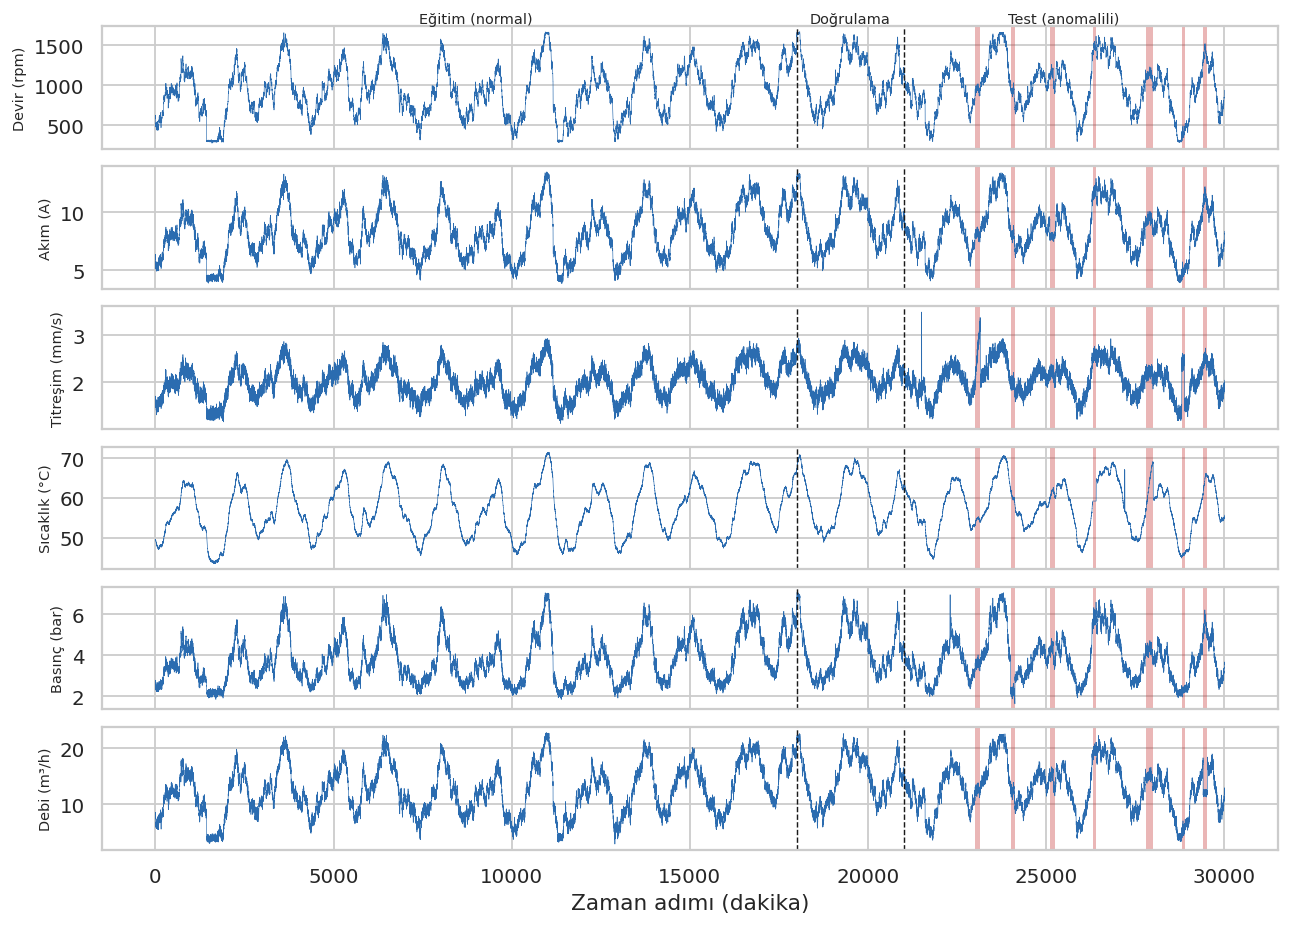

In [ ]:
# Görsel 1: Zaman serileri
fig, axes = plt.subplots(6, 1, figsize=(10, 7.2), sharex=True)
for ax, c in zip(axes, SENSORS):
    ax.plot(df.index, df[c], lw=0.35, color=C_NORM)
    ax.set_ylabel(LABELS[c], fontsize=8)
    for (s, L, *_ ) in EVENTS:
        ax.axvspan(s, s + L, color=C_ANOM, alpha=0.35, lw=0)
    for b in (TR_END, VA_END):
        ax.axvline(b, color="k", ls="--", lw=0.8)
axes[0].text(TR_END / 2, axes[0].get_ylim()[1], "Eğitim (normal)", ha="center", va="bottom", fontsize=8)
axes[0].text((TR_END + VA_END) / 2, axes[0].get_ylim()[1], "Doğrulama", ha="center", va="bottom", fontsize=8)
axes[0].text((VA_END + N) / 2, axes[0].get_ylim()[1], "Test (anomalili)", ha="center", va="bottom", fontsize=8)
axes[-1].set_xlabel("Zaman adımı (dakika)")
fig.tight_layout(); fig.savefig(f"{OUT}/fig1_zaman_serileri.png"); plt.show()

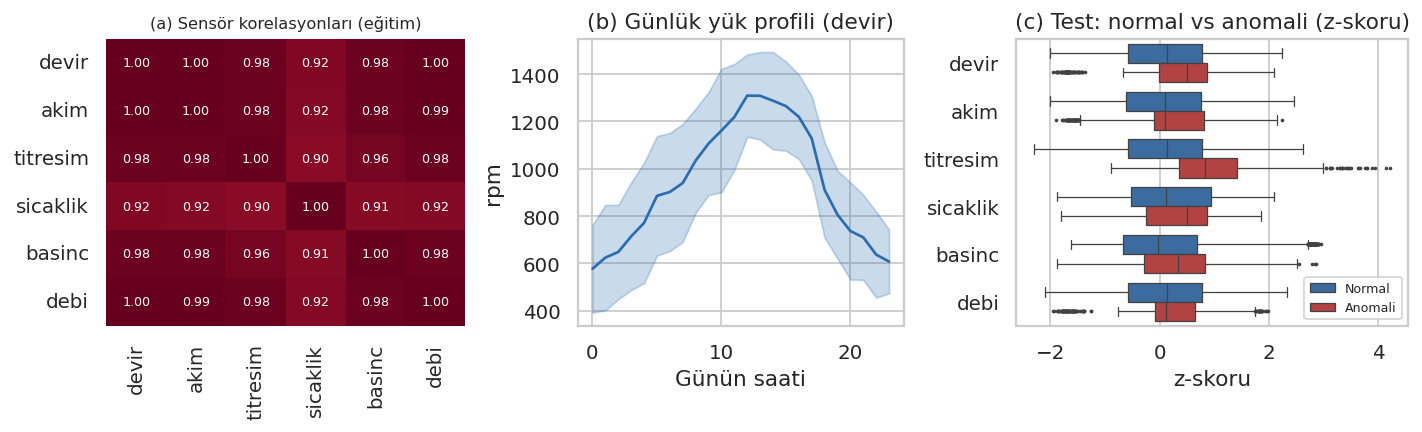

In [ ]:
# Görsel 2: (a) korelasyon, (b) günlük yük profili, (c) normal vs anomali dağılımı
train_raw = df.iloc[:TR_END]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.1, 1, 1.2]})
corr = train_raw[SENSORS].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0],
            cbar=False, annot_kws={"size": 7}, xticklabels=SENSORS, yticklabels=SENSORS)
axes[0].set_title("(a) Sensör korelasyonları (eğitim)", fontsize=9)
hour = (train_raw.index.values % 1440) // 60
g = train_raw.groupby(hour)["devir"]
axes[1].plot(g.mean().index, g.mean().values, color=C_NORM)
axes[1].fill_between(g.mean().index, g.mean() - g.std(), g.mean() + g.std(), alpha=0.25, color=C_NORM)
axes[1].set(title="(b) Günlük yük profili (devir)", xlabel="Günün saati", ylabel="rpm")
test_raw = df.iloc[VA_END:]
z = (test_raw[SENSORS] - train_raw[SENSORS].mean()) / train_raw[SENSORS].std()
zl = z.assign(durum=np.where(test_raw.anomali == 1, "Anomali", "Normal")).melt(id_vars="durum")
sns.boxplot(data=zl, x="value", y="variable", hue="durum", ax=axes[2], fliersize=1, linewidth=0.7,
            palette={"Normal": C_NORM, "Anomali": C_ANOM})
axes[2].set(title="(c) Test: normal vs anomali (z-skoru)", xlabel="z-skoru", ylabel="")
axes[2].legend(fontsize=7, loc="lower right")
fig.tight_layout(); fig.savefig(f"{OUT}/fig2_eda.png"); plt.show()

## 3. Ön işleme
* Eksik değer / yinelenen kayıt kontrolü
* `StandardScaler` **yalnızca eğitim verisinde** fit edilir (veri sızıntısını önlemek için)
* 10 adımlık kayan pencere (stride = 1) → her örnek 10×6 = 60 özellik
* Zamansal bölme: eğitim (0–18.000, yalnızca normal) | doğrulama (18.000–21.000, normal) | test (21.000–30.000)
* Pencere etiketi: pencere içinde en az bir anomalili adım varsa 1

In [ ]:
print("Eksik değer:", int(df[SENSORS].isna().sum().sum()), "| yinelenen satır:", int(df[SENSORS].duplicated().sum()))
scaler = StandardScaler().fit(df.iloc[:TR_END][SENSORS])
Xs = scaler.transform(df[SENSORS])
yp = df["anomali"].values
ev = df["olay"].values

def make_windows(X, w):
    idx = np.arange(w - 1, len(X))                       # pencerenin son adımı
    Xw = np.stack([X[i - w + 1:i + 1].ravel() for i in idx])
    return Xw, idx

Xw, end_idx = make_windows(Xs, W)
yw = np.array([yp[i - W + 1:i + 1].max() for i in end_idx])
ew = np.array([ev[i - W + 1:i + 1].max() for i in end_idx])
m_tr = end_idx < TR_END
m_va = (end_idx >= TR_END) & (end_idx < VA_END)
m_te = end_idx >= VA_END
Xtr, Xva, Xte = Xw[m_tr], Xw[m_va], Xw[m_te]
yte, ete, idx_te = yw[m_te], ew[m_te], end_idx[m_te]
assert yw[m_tr].sum() == 0 and yw[m_va].sum() == 0
print(f"Pencere sayıları → eğitim: {len(Xtr)}, doğrulama: {len(Xva)}, test: {len(Xte)}")
print(f"Test pencerelerinde anomali oranı: %{100*yte.mean():.1f} ({yte.sum()} / {len(yte)})")

Eksik değer: 0 | yinelenen satır: 0
Pencere sayıları → eğitim: 17991, doğrulama: 3000, test: 9000
Test pencerelerinde anomali oranı: %11.4 (1022 / 9000)


## 4. Model: Dense Autoencoder
`60 → 32 → 16 → 8 (darboğaz) → 16 → 32 → 60`, gizli katmanlarda ReLU, çıkışta doğrusal aktivasyon,
kayıp fonksiyonu MSE (yeniden oluşturma hatası), optimizer Adam (lr = 1e-3), L2 = 1e-5, batch = 256.
Model yalnızca normal pencereleri yeniden oluşturmayı öğrenir; normal dışı örnekler yüksek hata üretir.
En iyi doğrulama kaybına göre erken durdurma (patience = 20) uygulanır.

epoch   1 | train MSE 0.1250 | val MSE 0.1569
epoch  10 | train MSE 0.0149 | val MSE 0.0158
epoch  20 | train MSE 0.0139 | val MSE 0.0148
epoch  30 | train MSE 0.0114 | val MSE 0.0117
epoch  40 | train MSE 0.0110 | val MSE 0.0112
epoch  50 | train MSE 0.0107 | val MSE 0.0109
epoch  60 | train MSE 0.0104 | val MSE 0.0106
epoch  70 | train MSE 0.0102 | val MSE 0.0104
epoch  80 | train MSE 0.0099 | val MSE 0.0102
epoch  90 | train MSE 0.0099 | val MSE 0.0102
epoch 100 | train MSE 0.0098 | val MSE 0.0101
epoch 110 | train MSE 0.0098 | val MSE 0.0101
epoch 120 | train MSE 0.0098 | val MSE 0.0101
epoch 130 | train MSE 0.0095 | val MSE 0.0097
epoch 140 | train MSE 0.0095 | val MSE 0.0096
epoch 150 | train MSE 0.0094 | val MSE 0.0096
epoch 160 | train MSE 0.0094 | val MSE 0.0096
epoch 170 | train MSE 0.0094 | val MSE 0.0096
epoch 180 | train MSE 0.0094 | val MSE 0.0095
epoch 190 | train MSE 0.0094 | val MSE 0.0095
epoch 200 | train MSE 0.0094 | val MSE 0.0095
epoch 210 | train MSE 0.0094 | val

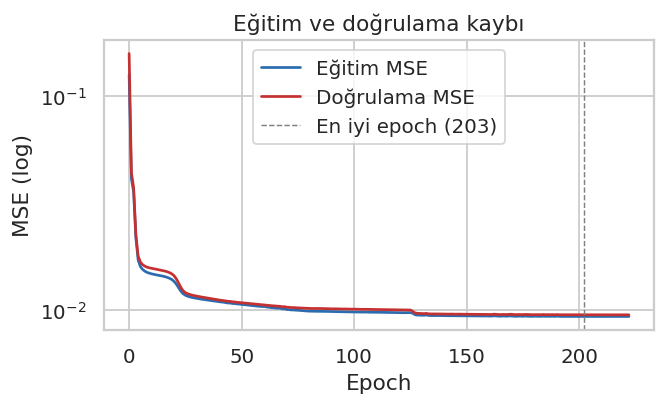

In [ ]:
ae = MLPRegressor(hidden_layer_sizes=(32, 16, 8, 16, 32), activation="relu", solver="adam",
                  learning_rate_init=1e-3, batch_size=256, alpha=1e-5, shuffle=True, random_state=SEED)
mse = lambda a, b: float(np.mean((a - b) ** 2))
hist = {"train": [], "val": []}
best, best_ep, wait, PATIENCE, MAX_EP = np.inf, 0, 0, 20, 400
for ep in range(1, MAX_EP + 1):
    ae.partial_fit(Xtr, Xtr)                         # 1 epoch
    tr_l, va_l = mse(ae.predict(Xtr), Xtr), mse(ae.predict(Xva), Xva)
    hist["train"].append(tr_l); hist["val"].append(va_l)
    if va_l < best - 1e-5:
        best, best_ep, wait = va_l, ep, 0
        best_w = (copy.deepcopy(ae.coefs_), copy.deepcopy(ae.intercepts_))
    else:
        wait += 1
    if ep % 10 == 0 or ep == 1:
        print(f"epoch {ep:3d} | train MSE {tr_l:.4f} | val MSE {va_l:.4f}")
    if wait >= PATIENCE:
        print(f"Erken durdurma: epoch {ep}, en iyi epoch {best_ep}"); break
ae.coefs_, ae.intercepts_ = best_w
print(f"En iyi doğrulama MSE: {best:.4f} (epoch {best_ep})")

fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.plot(hist["train"], label="Eğitim MSE", color=C_NORM)
ax.plot(hist["val"], label="Doğrulama MSE", color=C_ANOM)
ax.axvline(best_ep - 1, color="gray", ls="--", lw=0.8, label=f"En iyi epoch ({best_ep})")
ax.set(xlabel="Epoch", ylabel="MSE (log)", yscale="log", title="Eğitim ve doğrulama kaybı"); ax.legend()
fig.tight_layout(); fig.savefig(f"{OUT}/fig3_kayip.png"); plt.show()

## 5. Anomali skoru ve eşik
Skor = pencere başına ortalama kare hata. **Eşik:** doğrulama (normal) skorlarının %99'luncu yüzdeliği.
Etiketler eşik seçiminde kullanılmaz. Karşılaştırma için PCA (doğrusal yeniden oluşturma) ve
Isolation Forest temel modelleri aynı kuralla değerlendirilir.

In [ ]:
def recon_err(model_pred, X):
    return np.mean((model_pred - X) ** 2, axis=1)

pca = PCA(n_components=0.95, random_state=SEED).fit(Xtr)
iso = IsolationForest(n_estimators=200, random_state=SEED, n_jobs=1).fit(Xtr)
score_fns = {
    "Autoencoder": lambda X: recon_err(ae.predict(X), X),
    "PCA": lambda X: recon_err(pca.inverse_transform(pca.transform(X)), X),
    "Isolation Forest": lambda X: -iso.score_samples(X),
}
S_va = {k: f(Xva) for k, f in score_fns.items()}
S_te = {k: f(Xte) for k, f in score_fns.items()}
PCT = 99
thr = {k: np.percentile(S_va[k], PCT) for k in score_fns}
print("PCA bileşen sayısı (%95 varyans):", pca.n_components_)
print({k: round(float(v), 4) for k, v in thr.items()})

PCA bileşen sayısı (%95 varyans): 1
{'Autoencoder': 0.0203, 'PCA': 0.1235, 'Isolation Forest': 0.6923}


In [ ]:
def metrics(y, s, t):
    p = (s > t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, p).ravel()
    return dict(precision=precision_score(y, p), recall=recall_score(y, p), f1=f1_score(y, p),
                accuracy=(tp + tn) / len(y), fpr=fp / (fp + tn), roc_auc=roc_auc_score(y, s),
                pr_auc=average_precision_score(y, s), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

res = {k: metrics(yte, S_te[k], thr[k]) for k in score_fns}
tab = pd.DataFrame(res).T[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "fpr"]].round(3)
print(tab)

# Eşik duyarlılığı (Autoencoder)
sens = []
for name, t in [("%95", np.percentile(S_va["Autoencoder"], 95)), ("%99", np.percentile(S_va["Autoencoder"], 99)),
                ("%99,5", np.percentile(S_va["Autoencoder"], 99.5)), ("%99,9", np.percentile(S_va["Autoencoder"], 99.9)),
                ("μ+3σ", S_va["Autoencoder"].mean() + 3 * S_va["Autoencoder"].std())]:
    m = metrics(yte, S_te["Autoencoder"], t)
    sens.append(dict(esik=name, deger=float(t), precision=m["precision"], recall=m["recall"], f1=m["f1"], fpr=m["fpr"]))
sens = pd.DataFrame(sens); print(sens.round(3))

                  accuracy  precision  recall     f1  roc_auc  pr_auc    fpr
Autoencoder          0.958      0.948   0.662  0.780    0.861   0.773  0.005
PCA                  0.940      0.779   0.661  0.715    0.892   0.782  0.024
Isolation Forest     0.882      0.000   0.000  0.000    0.720   0.206  0.005
    esik  deger  precision  recall     f1    fpr
0    %95  0.015      0.710   0.709  0.710  0.037
1    %99  0.020      0.948   0.662  0.780  0.005
2  %99,5  0.024      0.973   0.645  0.776  0.002
3  %99,9  0.028      0.980   0.636  0.772  0.002
4   μ+3σ  0.019      0.933   0.666  0.777  0.006


## 6. Değerlendirme grafikleri

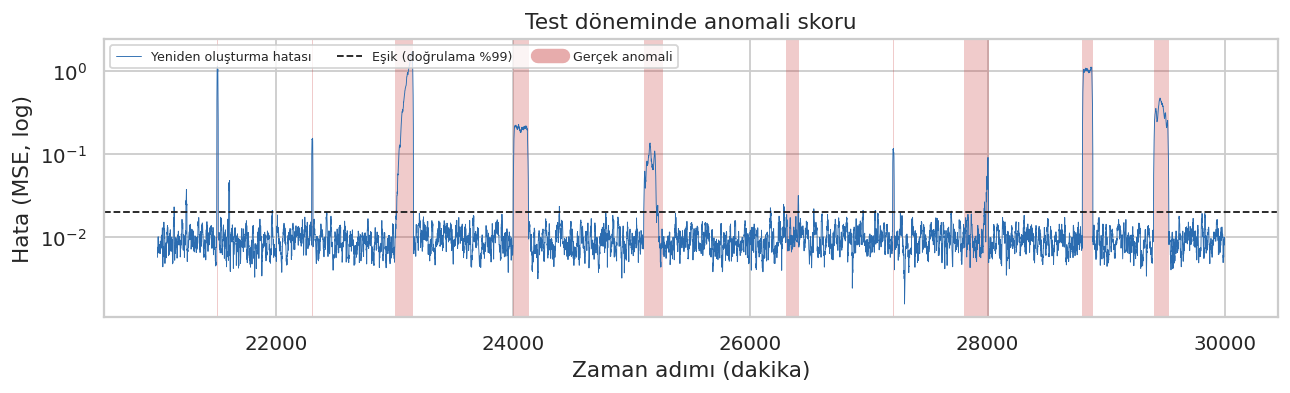

In [ ]:
s_ae = S_te["Autoencoder"]; alarm = s_ae > thr["Autoencoder"]
fig, ax = plt.subplots(figsize=(10, 3.1))
ax.plot(idx_te, s_ae, lw=0.5, color=C_NORM, label="Yeniden oluşturma hatası")
ax.axhline(thr["Autoencoder"], color="k", ls="--", lw=1, label=f"Eşik (doğrulama %{PCT})")
for (s, L, *_ ) in EVENTS:
    ax.axvspan(s, s + L + W - 1, color=C_ANOM, alpha=0.25, lw=0)
ax.plot([], [], color=C_ANOM, alpha=0.4, lw=8, label="Gerçek anomali")
ax.set(yscale="log", xlabel="Zaman adımı (dakika)", ylabel="Hata (MSE, log)", title="Test döneminde anomali skoru")
ax.legend(loc="upper left", ncol=3, fontsize=7)
fig.tight_layout(); fig.savefig(f"{OUT}/fig4_skor.png"); plt.show()

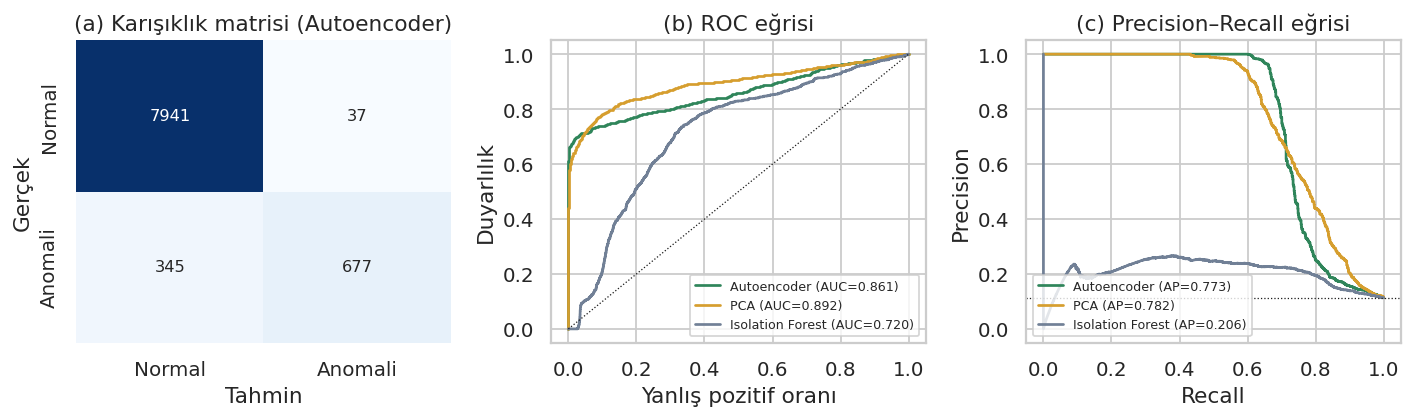

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
cm = confusion_matrix(yte, alarm.astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Normal", "Anomali"], yticklabels=["Normal", "Anomali"])
axes[0].set(title="(a) Karışıklık matrisi (Autoencoder)", xlabel="Tahmin", ylabel="Gerçek")
cols = {"Autoencoder": C_AE, "PCA": "#d69e2e", "Isolation Forest": "#718096"}
for k in score_fns:
    fpr_, tpr_, _ = roc_curve(yte, S_te[k]); axes[1].plot(fpr_, tpr_, color=cols[k], label=f"{k} (AUC={res[k]['roc_auc']:.3f})")
    p_, r_, _ = precision_recall_curve(yte, S_te[k]); axes[2].plot(r_, p_, color=cols[k], label=f"{k} (AP={res[k]['pr_auc']:.3f})")
axes[1].plot([0, 1], [0, 1], "k:", lw=0.7); axes[1].set(title="(b) ROC eğrisi", xlabel="Yanlış pozitif oranı", ylabel="Duyarlılık")
axes[2].axhline(yte.mean(), color="k", ls=":", lw=0.7); axes[2].set(title="(c) Precision–Recall eğrisi", xlabel="Recall", ylabel="Precision")
axes[1].legend(fontsize=7, loc="lower right"); axes[2].legend(fontsize=7, loc="lower left")
fig.tight_layout(); fig.savefig(f"{OUT}/fig5_degerlendirme.png"); plt.show()

## 7. Hata analizi
Olay (event) bazlı yakalama, gecikme ve hatayı en çok hangi sensörün oluşturduğu incelenir.

In [ ]:
rows = []
err_sensor = np.mean(((ae.predict(Xte) - Xte) ** 2).reshape(-1, W, len(SENSORS)), axis=1)   # pencere × sensör
for k, (s, L, typ, col, mag) in enumerate(EVENTS):
    m = ete == k
    det_win = alarm[m]
    first = idx_te[m][det_win.argmax()] if det_win.any() else None
    rows.append(dict(olay=f"E{k+1}", tur=typ, sensor=col, sure=L, pencere_recall=float(det_win.mean()),
                     yakalandi=bool(det_win.any()), gecikme=(int(first - s) if first is not None else None),
                     sensor_payi=(err_sensor[m].mean(0) / err_sensor[m].mean(0).sum()).tolist()))
ev_df = pd.DataFrame(rows)
print(ev_df[["olay", "tur", "sensor", "sure", "pencere_recall", "yakalandi", "gecikme"]].round(2))
normal_te = yte == 0
fa_share = err_sensor[normal_te & alarm].mean(0) if (normal_te & alarm).any() else np.zeros(len(SENSORS))
print("Yanlış alarm sayısı:", int((normal_te & alarm).sum()), "/", int(normal_te.sum()))

  olay                 tur    sensor  sure  pencere_recall  yakalandi  gecikme
0   E1         Ani sıçrama  titresim     4            1.00       True        0
1   E2         Ani sıçrama    basinc     3            1.00       True        0
2   E3       Kayma (drift)  titresim   150            0.90       True       14
3   E4      Seviye kayması    basinc   120            1.00       True        0
4   E5  Korelasyon kopması      akim   150            0.73       True        1
5   E6       Donmuş sensör  sicaklik   100            0.06       True      101
6   E7         Ani sıçrama  sicaklik     5            1.00       True        0
7   E8       Kayma (drift)  sicaklik   200            0.12       True      172
8   E9      Seviye kayması  titresim    80            1.00       True        0
9  E10  Korelasyon kopması      debi   120            1.00       True        0
Yanlış alarm sayısı: 37 / 7978


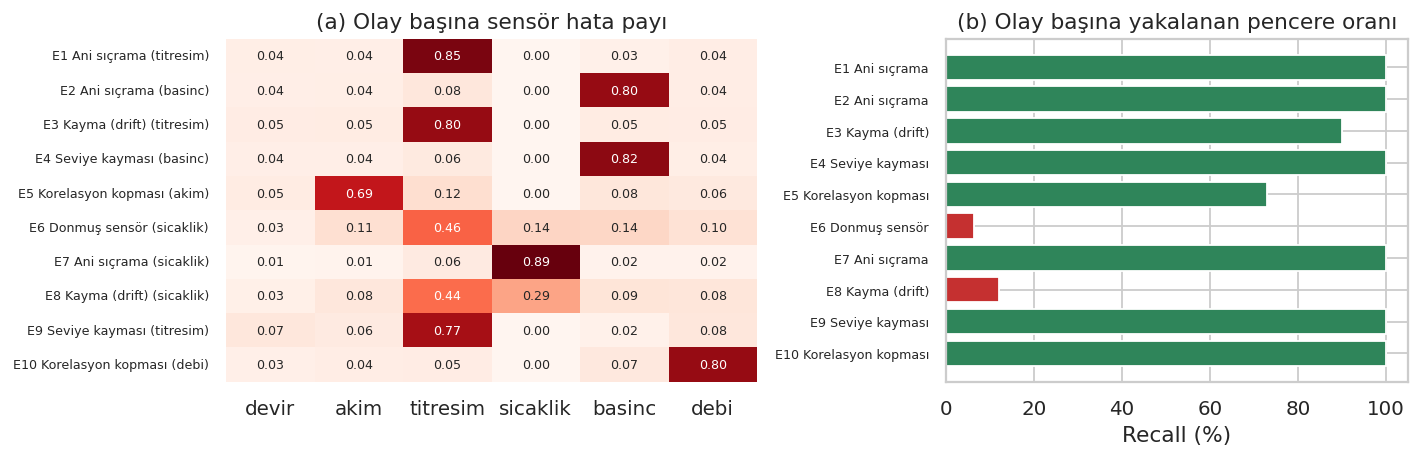

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.15, 1]})
share = np.array(ev_df["sensor_payi"].tolist())
sns.heatmap(share, annot=True, fmt=".2f", cmap="Reds", ax=axes[0], cbar=False, annot_kws={"size": 7},
            xticklabels=SENSORS, yticklabels=[f"{r.olay} {r.tur} ({r.sensor})" for r in ev_df.itertuples()])
axes[0].set(title="(a) Olay başına sensör hata payı"); axes[0].tick_params(axis="y", labelsize=7)
bars = axes[1].barh([f"{r.olay} {r.tur}" for r in ev_df.itertuples()][::-1], ev_df["pencere_recall"][::-1] * 100,
                    color=[C_AE if v > 0.5 else C_ANOM for v in ev_df["pencere_recall"][::-1]])
axes[1].set(title="(b) Olay başına yakalanan pencere oranı", xlabel="Recall (%)", xlim=(0, 105)); axes[1].tick_params(axis="y", labelsize=7)
fig.tight_layout(); fig.savefig(f"{OUT}/fig6_hata_analizi.png"); plt.show()

In [ ]:
# Yanlış negatif / yanlış pozitif dağılımı
fn_mask = (yte == 1) & (~alarm)
fn_per_event = {f"E{k+1}": int((fn_mask & (ete == k)).sum()) for k in range(len(EVENTS))}
fp_idx = idx_te[normal_te & alarm]
ends = np.array([s + L - 1 for (s, L, *_ ) in EVENTS])
after = [int(min([i - e for e in ends if i - e >= 0] or [10**9])) for i in fp_idx]
fp_after_event = int(sum(1 for a in after if a <= 60))
fp_clusters = int((np.diff(fp_idx) > 5).sum() + 1) if len(fp_idx) else 0
load_all = df["devir"].values
fp_rpm, nor_rpm = float(load_all[fp_idx].mean()), float(load_all[idx_te[normal_te]].mean())
print("FN olay dağılımı:", fn_per_event, "| toplam FN:", int(fn_mask.sum()))
print("FP sayısı:", len(fp_idx), "| bir olaydan sonraki 60 adımda:", fp_after_event, "| küme sayısı:", fp_clusters)
print("FP ortalama devir: %.0f | normal ortalama devir: %.0f" % (fp_rpm, nor_rpm))

FN olay dağılımı: {'E1': 0, 'E2': 0, 'E3': 16, 'E4': 0, 'E5': 43, 'E6': 102, 'E7': 0, 'E8': 184, 'E9': 0, 'E10': 0} | toplam FN: 345
FP sayısı: 37 | bir olaydan sonraki 60 adımda: 0 | küme sayısı: 12
FP ortalama devir: 930 | normal ortalama devir: 973


In [ ]:
summary = dict(
    n=N, anomaly_ratio_all=float(df.anomali.mean()), anomaly_ratio_test=float(df.anomali.iloc[VA_END:].mean()),
    windows=dict(train=int(len(Xtr)), val=int(len(Xva)), test=int(len(Xte)), test_anom=int(yte.sum())),
    best_epoch=int(best_ep), epochs_run=len(hist["train"]), best_val_mse=float(best),
    final_train_mse=float(hist["train"][best_ep - 1]), pca_components=int(pca.n_components_),
    threshold={k: float(v) for k, v in thr.items()}, results=res, sensitivity=sens.to_dict("records"),
    events=ev_df.drop(columns=["sensor_payi"]).to_dict("records"),
    event_detect_rate=float(ev_df["yakalandi"].mean()), false_alarms=int((normal_te & alarm).sum()),
    normal_test_windows=int(normal_te.sum()), fn_per_event=fn_per_event, fp_after_event=fp_after_event,
    fp_clusters=fp_clusters, fp_rpm=fp_rpm, normal_rpm=nor_rpm, corr=corr.round(2).to_dict())
json.dump(summary, open(f"{OUT}/sonuclar.json", "w"), ensure_ascii=False, indent=1, default=float)
print("Kaydedildi:", sorted(os.listdir(OUT)))

Kaydedildi: ['fig1_zaman_serileri.png', 'fig2_eda.png', 'fig3_kayip.png', 'fig4_skor.png', 'fig5_degerlendirme.png', 'fig6_hata_analizi.png', 'sonuclar.json']
